Convoluted audio saved as 'output_convoluted.wav'.


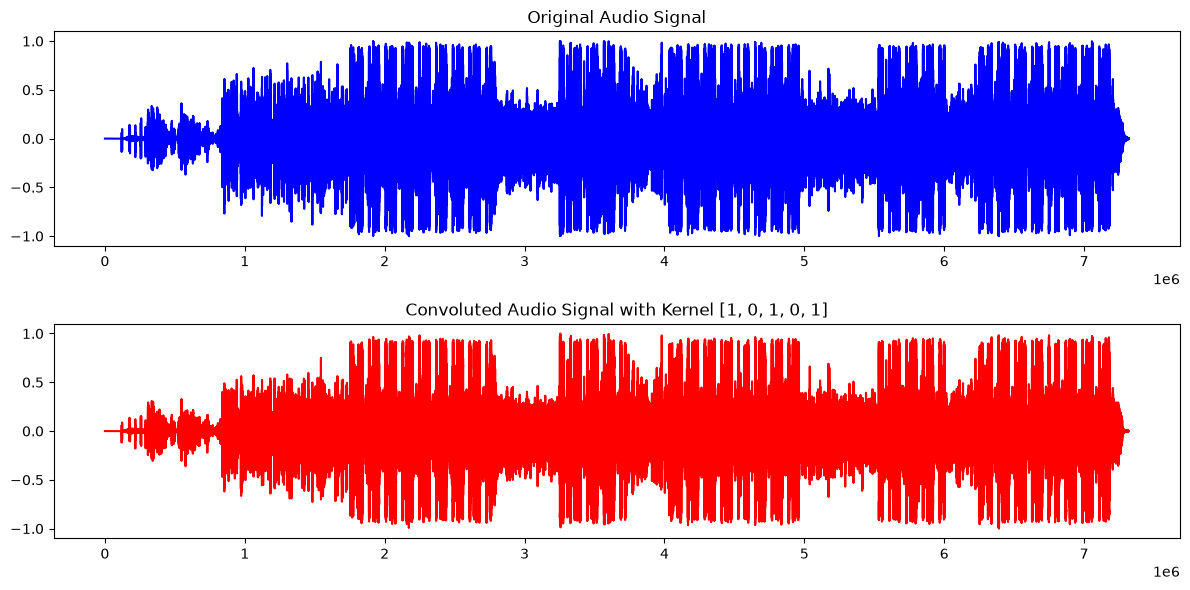

In [2]:
from pydub import AudioSegment 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.signal import convolve 
 
# Load MP3 file 
audio = AudioSegment.from_mp3("audio.mp3")  
 
# Convert to mono and extract raw samples 
audio = audio.set_channels(1) 
samples = np.array(audio.get_array_of_samples()).astype(np.float32) 
 
# Define convolution kernel 
# kernel = np.array([1, 0, 1, 0, 1], dtype=np.float32) 
kernel = np.array([255, 255, 255, 255, 255], dtype=np.float32)  
 
# Perform convolution 
convoluted = convolve(samples, kernel, mode='same') 
 
# Normalize to int16 range for saving 
convoluted = convoluted / np.max(np.abs(convoluted))  # Normalize to [-1, 1] 
convoluted_int16 = (convoluted * 32767).astype(np.int16)  # Scale to int16 
 
# Save as WAV using PyDub 
convoluted_audio = AudioSegment( 
    convoluted_int16.tobytes(), 
    frame_rate=audio.frame_rate, 
    sample_width=2,  # 16-bit samples = 2 bytes 
    channels=1 
) 
# Export to file 
convoluted_audio.export("output_convoluted.wav", format="wav") 
print("Convoluted audio saved as 'output_convoluted.wav'.") 
 
# Plot original and convoluted signals (optional) 
samples_norm = samples / np.max(np.abs(samples)) 
convoluted_norm = convoluted 
 
plt.figure(figsize=(12, 6)) 
plt.subplot(2, 1, 1) 
plt.plot(samples_norm, color='blue') 
plt.title("Original Audio Signal") 
plt.subplot(2, 1, 2) 
plt.plot(convoluted_norm, color='red') 
plt.title("Convoluted Audio Signal with Kernel [1, 0, 1, 0, 1]") 
plt.tight_layout() 
plt.show()